# Project 1, Phase 1: The ODE alone, no neural net

No network yet. First prove the ODE makes sensible curves. Run each cell top to bottom.

## The equations

Drug concentration, one compartment:

- dC/dt = -k_e * C, starting at Dose/V, with k_e = CL/V.

Tumour response, logistic growth minus drug kill:

- dT/dt = growth * T * (1 - T/K) - kill * C * T.

Teaching numbers: Dose 500 mg, CL 7.5 L/day, V 50 L, growth 0.2 per day, K 100, kill 0.05 per (mg/L) per day, starting tumour 10.

Note: Dose 500 (not 100) so the starting concentration, 10 mg/L, is strong enough to beat growth at first. With Dose 100 the tumour would never fall, and Phase 1 could not pass its check.

In [1]:
import torch
from torchdiffeq import odeint
import matplotlib.pyplot as plt

DOSE = 500.0
V = 50.0
GROWTH = 0.2
K = 100.0
KILL = 0.05
T0 = 10.0

def run(CL, days=30):
    ke = CL / V
    def ode(t, y):
        C, T = y[0], y[1]
        dC = -ke * C
        dT = GROWTH * T * (1 - T / K) - KILL * C * T
        return torch.stack([dC, dT])
    t = torch.linspace(0, days, days * 10 + 1)
    y0 = torch.tensor([DOSE / V, T0])
    sol = odeint(ode, y0, t)
    return t, sol[:, 0], sol[:, 1], ke

t, C, T, ke = run(7.5)
print("ke:", round(ke, 4), "per day, half life:", round(0.693 / ke, 1), "days")
print("Starting concentration:", round(DOSE / V, 1), "mg/L")
print("Tumour range:", round(T.min().item(), 2), "to", round(T.max().item(), 2))
print("Tumour at day 30:", round(T[-1].item(), 1))
assert not torch.isnan(C).any() and not torch.isnan(T).any()
print("Check passed: no NaN.")

Matplotlib is building the font cache; this may take a moment.


ke: 0.15 per day, half life: 4.6 days
Starting concentration: 10.0 mg/L
Tumour range: 4.27 to 55.87
Tumour at day 30: 55.9
Check passed: no NaN.


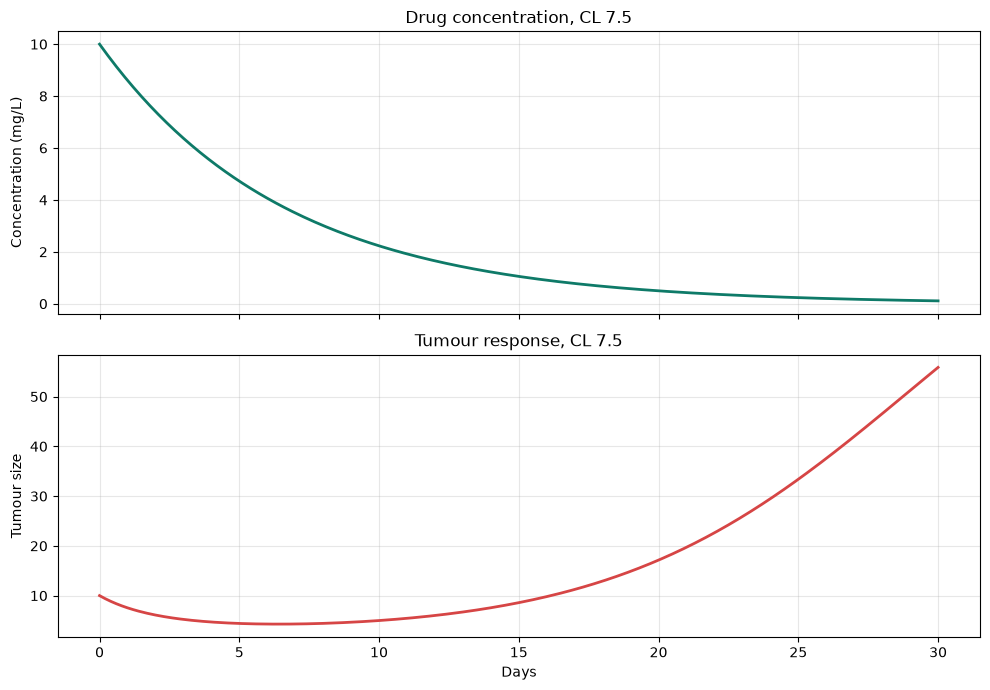

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t.numpy(), C.numpy(), color="#0E7A68", linewidth=2)
axes[0].set_ylabel("Concentration (mg/L)")
axes[0].set_title("Drug concentration, CL 7.5")
axes[0].grid(True, alpha=0.3)
axes[1].plot(t.numpy(), T.numpy(), color="#D64545", linewidth=2)
axes[1].set_ylabel("Tumour size")
axes[1].set_xlabel("Days")
axes[1].set_title("Tumour response, CL 7.5")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Change CL by hand

Same everything, only CL 7.5 goes to 3. Lower CL means slower clearance. Run and compare.

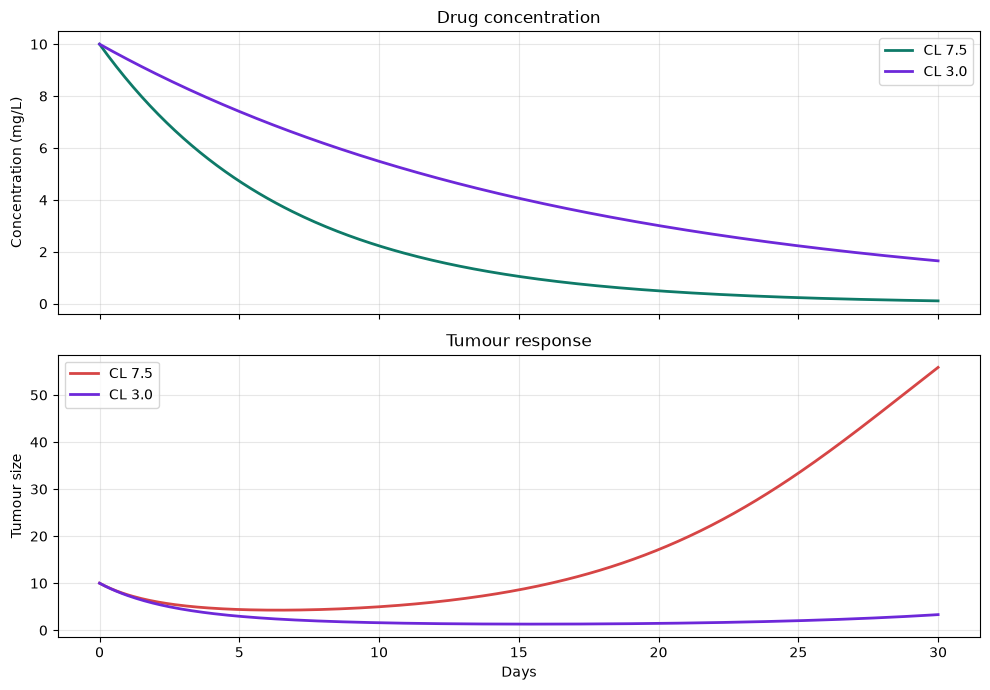

Tumour at day 30, CL 7.5: 55.9
Tumour at day 30, CL 3.0: 3.3
Lowest tumour, CL 7.5: 4.27  CL 3.0: 1.3


In [3]:
t3, C3, T3, ke3 = run(3.0)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t.numpy(), C.numpy(), color="#0E7A68", linewidth=2, label="CL 7.5")
axes[0].plot(t3.numpy(), C3.numpy(), color="#6D28D9", linewidth=2, label="CL 3.0")
axes[0].set_ylabel("Concentration (mg/L)")
axes[0].set_title("Drug concentration")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(t.numpy(), T.numpy(), color="#D64545", linewidth=2, label="CL 7.5")
axes[1].plot(t3.numpy(), T3.numpy(), color="#6D28D9", linewidth=2, label="CL 3.0")
axes[1].set_ylabel("Tumour size")
axes[1].set_xlabel("Days")
axes[1].set_title("Tumour response")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Tumour at day 30, CL 7.5:", round(T[-1].item(), 1))
print("Tumour at day 30, CL 3.0:", round(T3[-1].item(), 1))
print("Lowest tumour, CL 7.5:", round(T.min().item(), 2), " CL 3.0:", round(T3.min().item(), 2))

## Check

- No NaN, no errors.
- Tumour falls while the drug is present, then grows back as the drug clears.
- One sentence for CL: lower CL clears the drug more slowly, so the drug stays higher for longer, holds the tumour down longer, and the tumour is smaller at day 30.

If your plots look like that, Phase 1 is done. Save a copy in Drive, then tell Muse to start Phase 2.